# Customer Churn Analysis: Why Is a Retail Bank Losing Customers?

**Author:** Uzma Siddiqui  |  **Tools:** Python (pandas, matplotlib)

## Business problem

A retail bank has lost about one in five of its customers. Leadership wants to know **who is leaving, why, and which current customers we should contact before they leave too.** In this notebook I act as the bank's data analyst and answer those questions with Python.

## About the dataset

- **Name:** Churn Modelling
- **Source:** [Kaggle, Churn Modelling (shrutimechlearn)](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling), originally shared as course material by [SuperDataScience](https://www.superdatascience.com/pages/deep-learning)
- **Size:** 10,000 customers (rows) and 14 columns
- **Target column:** `Exited` (1 = the customer left the bank, 0 = still a customer)
- **License:** listed as "Unknown" on Kaggle, so I use it for learning and portfolio purposes only

| Column | What it tells us |
|---|---|
| `CustomerId` | Unique customer ID |
| `CreditScore` | Credit score (350 to 850) |
| `Geography` | Country/region: France, Germany or Spain |
| `Gender` | Male or Female |
| `Age` | Age in years |
| `Tenure` | Years as a customer |
| `Balance` | Money held in the account |
| `NumOfProducts` | Number of bank products held (1 to 4) |
| `HasCrCard` | 1 = has a credit card |
| `IsActiveMember` | 1 = actively uses the bank |
| `EstimatedSalary` | Estimated yearly income |
| `Exited` | 1 = left the bank, 0 = stayed |

**A note on the data:** real customer records from Canadian banks are private (protected by privacy law), so no public dataset of them exists. This is a well-known public dataset of anonymized bank customers, used here as a stand-in. I frame the business story for a Canadian retail bank, and I treat the three countries as three regions the bank serves.

## What I will do in this notebook

1. **Load and inspect** the data (shape, columns, summary statistics)
2. **Check data quality:** missing values, duplicate customers, and zero balances
3. **Measure overall churn:** what share of customers left?
4. **Compare churn across groups:** country, gender, age group, number of products, and activity level
5. **Compare leavers with stayers:** balance, salary and credit score
6. **Build a simple risk score** (1 point per risk factor) and test whether it works
7. **Create a call list** of current, high-risk customers with large balances
8. **Draw charts** and **save the results** for the SQL, Excel and Power BI parts of this project

In [1]:
import pandas as pd

In [2]:
# The dataset sits in the repo's data/ folder
df = pd.read_csv("../data/Churn_Modelling.csv")

## 1. Load and inspect

Before answering anything: what am I working with?

In [3]:
df.shape

(10000, 14)

In [4]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [5]:
df[["Age", "Balance", "CreditScore"]].describe()

,Age,Balance,CreditScore
count,10000.000000,10000.000000,10000.000000
mean,38.921800,76485.889288,650.528800
std,10.487806,62397.405202,96.653299
min,18.000000,0.000000,350.000000
25%,32.000000,0.000000,584.000000
50%,37.000000,97198.540000,652.000000
75%,44.000000,127644.240000,718.000000
max,92.000000,250898.090000,850.000000


`df.shape` returns (10000, 14): 10,000 customers (rows) and 14 columns. `describe()` gives a quick summary: an average age of 38.9 (youngest 18, oldest 92), an average balance of about 76,486, and credit scores from 350 to 850 (average about 650).

In [6]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2. Data quality

Are there gaps or mistakes that would make my answers wrong?

In [7]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
df["CustomerId"].duplicated().sum()

np.int64(0)

In [9]:
(df["Balance"] == 0).sum()

np.int64(3617)

In [10]:
(df["Balance"] == 0).mean() * 100

np.float64(36.17)

- `isnull().sum()` counts empty cells in each column: every column shows 0, so there are no missing values.
- `duplicated().sum()` counts customers listed twice: 0.
- `(df["Balance"] == 0).sum()` counts customers with a balance of exactly zero: 3,617.

**Result:** the data is complete and has no duplicates. About 36% of customers hold a zero balance. That is not an error; these are probably people who only hold a credit card and keep no savings with the bank.

## 3. Overall churn

In [11]:
# How many customers are we losing overall?
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [12]:
df["Exited"].mean()*100

np.float64(20.369999999999997)

**Result:** the bank lost 2,037 of 10,000 customers, a churn rate of 20.4%, or about one in five.

## 4. Churn by customer group

### Country
Which country loses the most customers? (In Excel the same result comes from `AVERAGEIF`.)

In [13]:
df.groupby("Geography")["Exited"].mean()*100

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64

In [14]:
df.groupby("Geography")["Exited"].agg(["count", "sum", "mean"])

,count,sum,mean
Geography,,,
France,5014,810,0.161548
Germany,2509,814,0.324432
Spain,2477,413,0.166734


**What it means for the bank:** Germany loses about one in three customers, double the rate of France and Spain. Germany has half as many customers as France but almost the same number of leavers. Something specific is going wrong there (pricing? branch service? a local competitor?), so it needs a closer look.

### Gender
Do women or men leave more often?

In [15]:
df.groupby("Gender")["Exited"].mean()*100

Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64

**Result:** 25.1% of women left compared with 16.5% of men. This is worth investigating: is the bank's service, product mix or marketing serving women less well? An analyst reports the pattern; the *why* usually needs a follow-up such as a customer survey.

### Age
Are older customers more likely to leave?

In [16]:
df.groupby("Exited")["Age"].mean()

Exited
0    37.408389
1    44.837997
Name: Age, dtype: float64

Customers who stayed average 37.4 years; customers who left average 44.8 years. Leavers are about 7 years older.

Group customers into age bands:

In [17]:
df["AgeGroup"] = pd.cut(df["Age"],
    bins=[17, 30, 45, 60, 100],
    labels=["18-30", "31-45", "46-60", "61+"]).astype(str)

df.groupby("AgeGroup")["Exited"].mean() * 100

AgeGroup
18-30     7.520325
31-45    15.740584
46-60    51.123254
61+      24.784483
Name: Exited, dtype: float64

**Result:** customers aged 46-60 leave at more than half, roughly seven times the rate of customers under 30. This is the biggest single risk group. These are often people at their peak earning and saving years, exactly the customers other banks want to win.

### Number of products
The bank assumes more products = more loyalty. Is that true?

In [18]:
df.groupby("NumOfProducts")["Exited"].agg(["count", "mean"])

,count,mean
NumOfProducts,,
1,5084,0.277144
2,4590,0.075817
3,266,0.827068
4,60,1.000000


**Result:** two products is the sweet spot; those customers rarely leave. But customers with 3 or 4 products leave at 83-100%, the opposite of what the bank expects. The bank may be pushing products on people who do not want them. Caution: only 326 customers hold 3-4 products, so this is a strong signal in a small group, and should be tested before any policy changes.

### Activity
Do inactive customers leave more often?

In [19]:
df.groupby("IsActiveMember")["Exited"].mean()*100

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64

**Result:** inactive customers leave at 26.9%, almost twice the rate of active ones (14.3%). Getting people to use their account (mobile app, direct deposit, bill payments) is probably one of the cheapest ways to reduce churn.

## 5. How leavers differ from stayers

Do customers with bigger balances leave?

In [20]:
df.groupby("Exited")["Balance"].mean()

Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64

**Result:** customers who left held about 18,000 more in their accounts on average, so the bank is losing money, not just headcount. Salary and credit score (below) are almost identical between leavers and stayers, so they do not explain who leaves. Age, products, activity and country do.

In [21]:
df.groupby("Exited")["EstimatedSalary"].mean()

Exited
0     99738.391772
1    101465.677531
Name: EstimatedSalary, dtype: float64

In [22]:
df.groupby("Exited")["CreditScore"].mean()

Exited
0    651.853196
1    645.351497
Name: CreditScore, dtype: float64

In [23]:
df["CreditBand"] = pd.cut(df["CreditScore"],
                          bins=[349, 499, 599, 699, 799, 850],
                          labels=["350-499", "500-599", "600-699", "700-799", "800-850"]).astype(str)

print((df.groupby("CreditBand")["Exited"].mean() * 100).round(1))


CreditBand
350-499    23.7
500-599    21.2
600-699    19.7
700-799    19.9
800-850    19.5
Name: Exited, dtype: float64


In [24]:
print(df["CreditBand"].value_counts())

CreditBand
600-699    3818
700-799    2493
500-599    2402
800-850     655
350-499     632
Name: count, dtype: int64


## 6. Risk score

Can we score each customer's chance of leaving? One point for every risk factor found above:

1. Aged 46-60 → +1
2. Holds 3 or more products → +1
3. Inactive member → +1
4. Lives in Germany → +1

In [25]:
df["RiskPoints"] = 0
df.loc[df["Age"].between(46,60), "RiskPoints"] += 1
df.loc[df["NumOfProducts"] >= 3, "RiskPoints"] += 1
df.loc[df["IsActiveMember"] == 0, "RiskPoints"] += 1
df.loc[df["Geography"] == "Germany", "RiskPoints"] +=1

In [26]:
df.groupby("RiskPoints")["Exited"].agg(["count","mean"])

,count,mean
RiskPoints,,
0,3213,0.066916
1,4638,0.160414
2,1778,0.429696
3,347,0.835735
4,24,1.000000


| Risk points | Customers | Share who left |
|---|---|---|
| 0 | 3,213 | 6.7% |
| 1 | 4,638 | 16.0% |
| 2 | 1,778 | 43.0% |
| 3 | 347 | 83.6% |
| 4 | 24 | 100% |

The more points, the more people left. A rule this simple sorts customers very well.

In [27]:
# Group the points into three easy labels
df["RiskLevel"] = pd.cut(df["RiskPoints"],
            bins=[-1, 1, 2, 4],
            labels=["Low", "Medium", "High"]).astype(str)

df.groupby("RiskLevel")["Exited"].agg(["count", "mean"])

,count,mean
RiskLevel,,
High,371,0.846361
Low,7851,0.122150
Medium,1778,0.429696


**Result:** Low 12.2%, Medium 43.0%, High 84.6% of customers actually left. A 4-point scorecard anyone can understand: customers scoring 0-1 leave 12% of the time; customers scoring 3-4 leave 85% of the time.

The same score broken into its four flags, so each customer's warning signs are visible:

In [28]:
df["Age46_60"]     = df["Age"].between(46, 60).astype(int)
df["Products3plus"] = (df["NumOfProducts"] >= 3).astype(int)
df["Inactive"]     = (df["IsActiveMember"] == 0).astype(int)
df["Germany"]      = (df["Geography"] == "Germany").astype(int)

df["RiskPoints"] = df["Age46_60"] + df["Products3plus"] + df["Inactive"] + df["Germany"]

df[["Age46_60", "Products3plus", "Inactive", "Germany", "RiskPoints"]].head(10)

,Age46_60,Products3plus,Inactive,Germany,RiskPoints
0,0,0,0,0,0
1,0,0,0,0,0
2,0,1,1,0,2
3,0,0,1,0,1
4,0,0,0,0,0
5,0,0,1,0,1
6,1,0,0,0,1
7,0,1,1,1,3
8,0,0,0,0,0
9,0,0,0,0,0


## 7. Retention call list

Who should the retention team call before they leave? Current customers with 2+ warning signs and a balance over 100,000.

In [29]:
still_here = df[df["Exited"] == 0]

In [30]:
call_list = still_here[(still_here["RiskPoints"] >= 2) & (still_here["Balance"] > 100000)]
len(call_list)

713

In [31]:
call_list["Balance"].sum()

np.float64(94834039.18)

In [32]:
call_list.sort_values("Balance", ascending=False).head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,...,EstimatedSalary,Exited,AgeGroup,CreditBand,RiskPoints,RiskLevel,Age46_60,Products3plus,Inactive,Germany
1067,1068,15599131,Dilke,650,Germany,Male,26,4,214346.96,2,...,128815.33,0,18-30,600-699,2,Medium,0,0,1,1
3920,3921,15620268,Thomson,634,Germany,Male,43,3,212696.32,1,...,115268.86,0,31-45,600-699,2,Medium,0,0,1,1
7887,7888,15745433,Conti,716,Germany,Female,30,2,205770.78,2,...,65464.66,0,18-30,700-799,2,Medium,0,0,1,1
8063,8064,15663888,Connor,549,Germany,Male,34,6,204017.40,2,...,109538.35,0,31-45,500-599,2,Medium,0,0,1,1
9833,9834,15807245,McKay,699,Germany,Female,41,1,200117.76,2,...,94142.35,0,31-45,600-699,2,Medium,0,0,1,1
932,933,15634141,Shephard,708,Germany,Female,42,8,192390.52,2,...,823.36,0,31-45,700-799,2,Medium,0,0,1,1
5604,5605,15804721,Boni,602,France,Male,49,0,191808.73,1,...,97640.20,0,46-60,600-699,2,Medium,1,0,1,0
177,178,15790355,Okechukwu,606,Germany,Male,36,5,190479.48,2,...,179351.89,0,31-45,600-699,2,Medium,0,0,1,1
8188,8189,15623314,Tucker,506,Germany,Female,59,3,190353.08,1,...,78365.75,0,46-60,500-599,3,High,1,0,1,1
2171,2172,15747174,Hao,526,Germany,Male,58,9,190298.89,2,...,191263.76,0,46-60,500-599,2,Medium,1,0,0,1


**Result:** 713 customers are on the list. Together they hold about 94.8 million (exactly 94,834,039).

There are 713 current customers who show two or more warning signs and hold over 100K each, about 94.8 million sitting in accounts that look likely to leave. Calling the largest balances first protects the most money first.

## 8. Charts

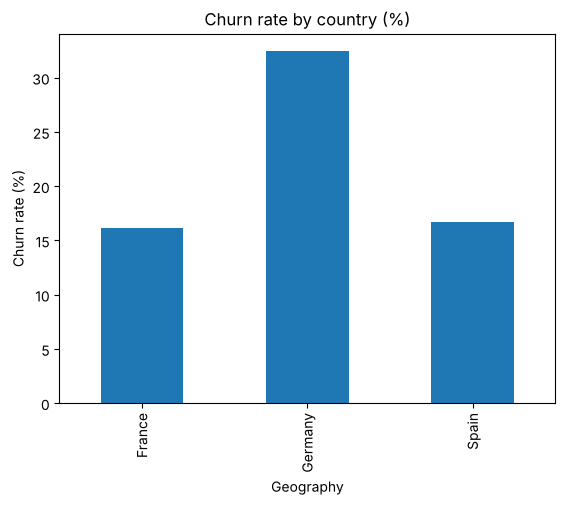

In [33]:
import matplotlib.pyplot as plt
(df.groupby("Geography")["Exited"].mean() * 100).plot(
    kind="bar",
    title="Churn rate by country (%)"
)
plt.ylabel("Churn rate (%)")
plt.show()

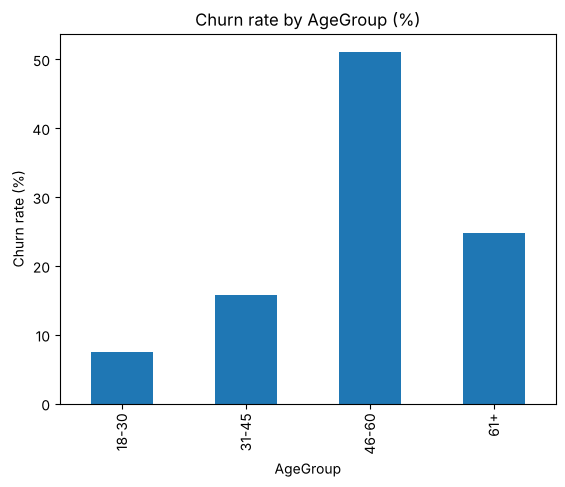

In [34]:
(df.groupby("AgeGroup")["Exited"].mean() * 100).plot( 
    kind="bar", 
    title="Churn rate by AgeGroup (%)")
plt.ylabel("Churn rate (%)")
plt.show()

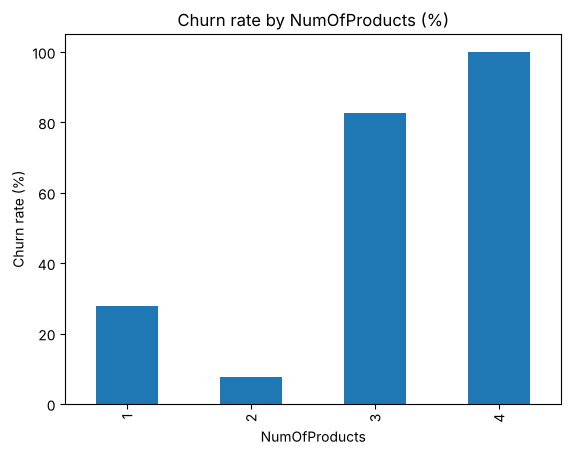

In [35]:
(df.groupby("NumOfProducts")["Exited"].mean() * 100).plot(
    kind="bar", title="Churn rate by NumOfProducts (%)")
plt.ylabel("Churn rate (%)")
plt.show()

## 9. Save results

In [36]:
# Save results for the SQL, Excel and Power BI parts of the project
import os
os.makedirs("../outputs", exist_ok=True)
df.to_csv("../outputs/bank_customers_with_risk.csv", index=False)

In [37]:
call_list.sort_values("Balance", ascending=False).to_csv("../outputs/call_list.csv", index=False)

## Summary

**Findings**
1. 20.4% of customers left (2,037 of 10,000).
2. Risk is concentrated in customers aged 46-60 (51% left), customers with 3-4 products (83-100% left), inactive customers (27% vs 14%), and Germany (32% vs about 16%).
3. Customers who left held higher balances on average (91K vs 73K), so the money lost is bigger than the headcount suggests.

**Recommendations**
1. Call the 713 high-balance, high-risk current customers, starting with the largest balances.
2. Investigate why Germany churns at double the rate of the other markets.
3. Review the 3+ product sales approach, and run a small test before changing policy, because the group is small.

**Limitation:** this is an anonymized public dataset. It shows patterns, not proof of why customers leave.